In [22]:
import torch
from torch import nn
import pandas as pd
import matplotlib.pyplot as plt


In [23]:
students = pd.read_csv("students_100.csv")

X = torch.tensor(
    students[["study_hours","phone_hours"]].values,
    dtype=torch.float32
)

Y = torch.tensor(
    students[["maths"]].values,
    dtype=torch.float32
)

print(X.shape, Y.shape)


torch.Size([100, 2]) torch.Size([100, 1])


Epoch 0: Loss = 3031.186767578125
Epoch 10: Loss = 614.9981079101562
Epoch 20: Loss = 332.93243408203125
Epoch 30: Loss = 188.58523559570312
Epoch 40: Loss = 147.23912048339844
Epoch 50: Loss = 117.65035247802734
Epoch 60: Loss = 98.97533416748047
Epoch 70: Loss = 87.12096405029297
Epoch 80: Loss = 80.0728988647461
Epoch 90: Loss = 75.26002502441406
Epoch 100: Loss = 71.23714447021484
Epoch 110: Loss = 67.49031066894531
Epoch 120: Loss = 64.03317260742188
Epoch 130: Loss = 60.97837829589844
Epoch 140: Loss = 58.341617584228516
Epoch 150: Loss = 56.118812561035156
Epoch 160: Loss = 54.31302261352539
Epoch 170: Loss = 52.902862548828125
Epoch 180: Loss = 51.8491096496582
Epoch 190: Loss = 51.098472595214844
Epoch 200: Loss = 50.59052658081055
Epoch 210: Loss = 50.264766693115234
Epoch 220: Loss = 50.067081451416016
Epoch 230: Loss = 49.953697204589844
Epoch 240: Loss = 49.89228820800781
Epoch 250: Loss = 49.86088943481445
Epoch 260: Loss = 49.845767974853516
Epoch 270: Loss = 49.83890151

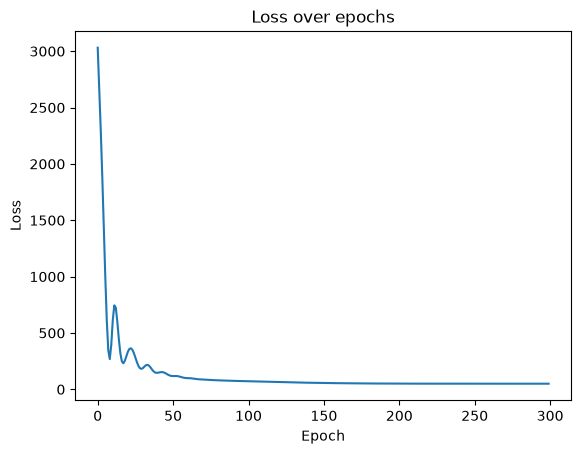

In [31]:
torch.manual_seed(42)

model = nn.Sequential(
    nn.Linear(2, 3),
    nn.ReLU(),
    nn.Linear(3, 1),
)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.2)

losses = []
for epoch in range(300):
    guess = model(X)
    loss = loss_fn(guess, Y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 10 == 0:
        print(f"Epoch {epoch}: Loss = {loss.item()}")

plt.plot(losses)
plt.title("Loss over epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

In [32]:
with torch.no_grad():
    new_data = torch.tensor([[5, 2]], dtype=torch.float32)
    
    print("5 study hours, 0 phone hours -",round(model(new_data).item(), 2),"marks")

    

5 study hours, 0 phone hours - 80.69 marks
